# Instructions

1. Première convolution
    - Convoler $x = [1, 0.5]$ et $y = [1, 0, 0, 0.8]$
    - Tracer le résultat
    - Prévoir (sur papier) le résultat de la convolution entre $[1, 0, 1]$ et $[1, 0.5, 0, -1]$, vérifier via l'implémentation

2. Convolution d'un signal audio
    - Charger le fichier drums.wav. 
    - Le convoler avec un signal $y$ créé de sorte à ce que le résultat de la convolution soit le signal original joué deux fois : une sans retard avec un gain de 1 l'autre avec 0.1 secondes de retard et un gain de 0.5.
    - Tracer et écouter le résultat

3. Convolution d'un signal audio et d'une réponse impulsionnelle
    - Charger les fichiers drums.wav et ir_mono, les tracer
    - Les convoler, tracer et écouter le résultat

4. Convolution circulaire

# Correction

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

## 1. Première convolution

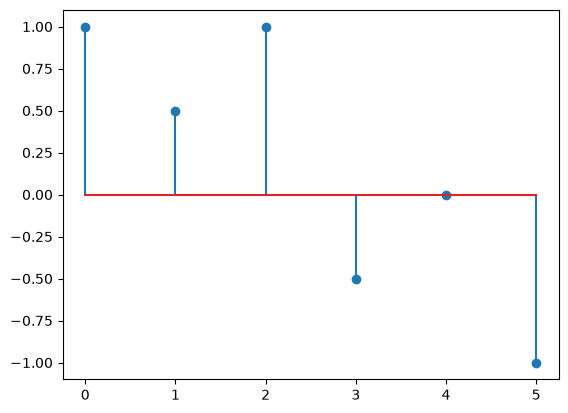

In [3]:
# create inputs
x = np.array([1, 0.5])
y = np.array([1, 0, 0, 0.8])

x = np.array([1, 0, 1])
y = np.array([1, 0.5, 0, -1])

# convolve
z = np.convolve(x, y)

# plot
plt.stem(z);

## 2. Convolution d'un signal audio

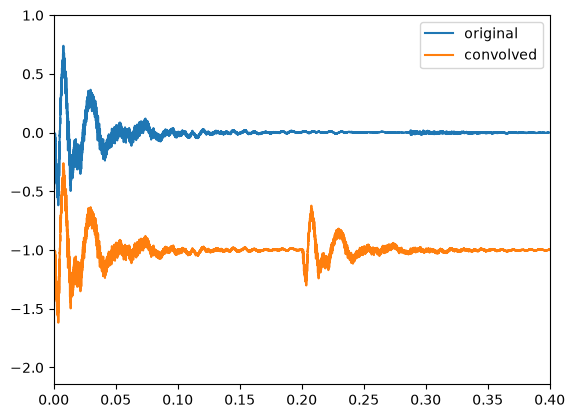

In [4]:
# load audio
fs, audio = scipy.io.wavfile.read('../assets/drums.wav')
audio = audio / np.max(np.abs(audio))

# convolve
delay_in_sec = 0.2
x = np.zeros(round(fs*delay_in_sec))
x[1] = 1; x[-1] = 0.5
audio_out = np.convolve(audio, x)

# play 
display(Audio(audio, rate=fs))

# plot
t = np.arange(len(audio))/fs
plt.plot(t, audio, label='original')
t = np.arange(len(audio_out))/fs
plt.plot(t, audio_out-1, label='convolved')
plt.xlim([0,2*delay_in_sec])
plt.legend()
plt.show()

# play 
display(Audio(audio_out, rate=fs))


## 3. Convolution d'un signal audio et d'une réponse impulsionnelle

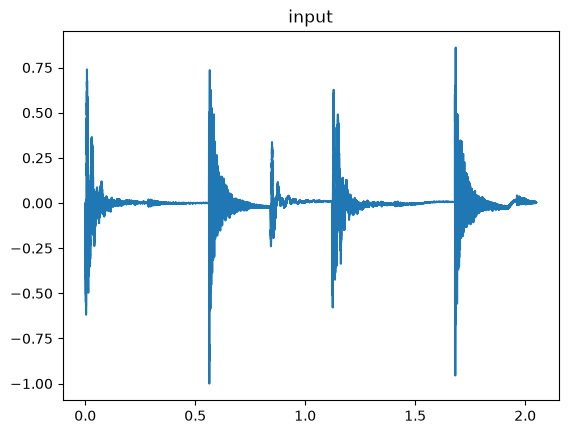

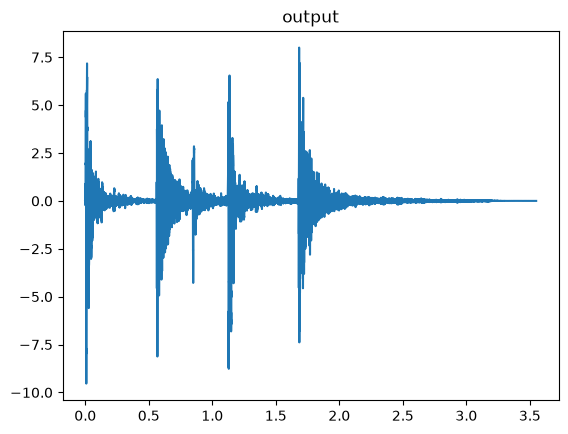

In [5]:
# load audio
fs, audio = scipy.io.wavfile.read('../assets/drums.wav')
fs_ir, ir = scipy.io.wavfile.read('../assets/ir_mono.wav')

# normalise 
audio = audio / np.max(np.abs(audio))
ir = ir / np.max(np.abs(ir))

## truncate (debug)
# audio = audio[0:int(fs/4)]

# play 
display(Audio(audio, rate=fs))

# plot
t = np.arange(len(audio))/fs
plt.plot(t, audio)
plt.title('input')
plt.show()

# convolve
audio_out = np.convolve(audio, ir)

# play 
display(Audio(audio_out, rate=fs))

# plot
t = np.arange(len(audio_out))/fs
plt.plot(t, audio_out)
plt.title('output')
# plt.xlim([0,2*delay_in_sec])
plt.show()


## 4. Convolution temporelle -> multiplication fréquentielle et convolution circulaire

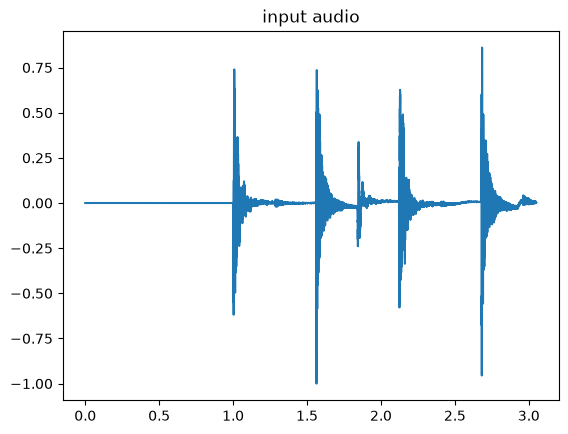

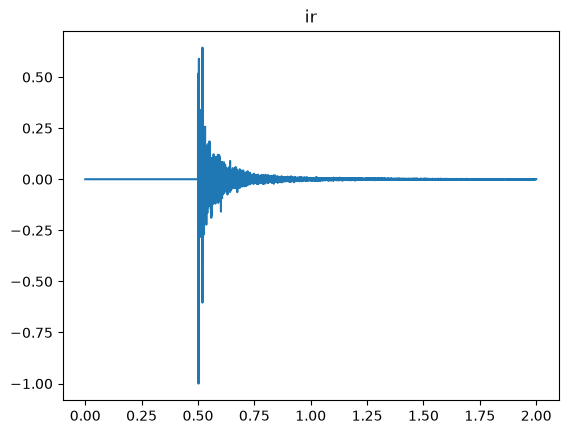

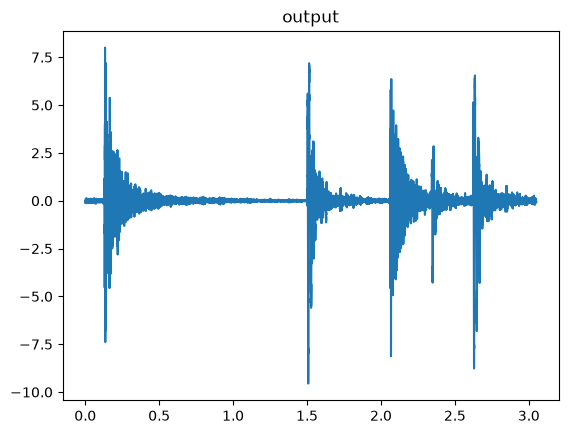

In [ ]:
# load audio
fs, audio = scipy.io.wavfile.read('../assets/drums_delayed2.wav')
fs_ir, ir = scipy.io.wavfile.read('../assets/ir_mono_delayed.wav')

# normalise 
audio = audio / np.max(np.abs(audio))
ir = ir / np.max(np.abs(ir))

# debug: crop 
# ir = ir[0:int(fs)]

# # debug: zero pad 
# audio = np.pad(audio, (fs, 0))
# ir = np.pad(ir, (int(0.5*fs), 0))

# play 
display(Audio(audio, rate=fs))

# plot
t = np.arange(len(audio))/fs
plt.plot(t, audio)
plt.title('input audio')
plt.show()

# play 
display(Audio(ir, rate=fs))

# plot
t = np.arange(len(ir))/fs
plt.plot(t, ir)
plt.title('ir')
plt.show()

# fft
# n = len(audio) + len(ir) - 1 # right
n = len(audio) # wrong
X = np.fft.rfft(audio, n)
H = np.fft.rfft(ir, n)

# multiply
Y = H * X

# ifft
audio_out = np.fft.irfft(Y, n)

# play 
display(Audio(audio_out, rate=fs))

# plot
t = np.arange(len(audio_out))/fs
plt.plot(t, audio_out)
plt.title('output audio')
plt.show()


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

# Short signal and impulse response
audio = np.array([1, 2, 3, 4, 5])
ir = np.array([1, 0.5, 0.25])

# Circular convolution (n = 5)
n = max(len(audio), len(ir))

X = np.fft.rfft(audio, n)
H = np.fft.rfft(ir, n)

y_circular = np.fft.irfft(X * H, n)

# Linear convolution (length = 7)
y_linear = fftconvolve(audio, ir)

print("Circular:", np.round(y_circular, 2))
print("Linear:  ", np.round(y_linear, 2))

Circular: [4.5  3.75 4.25 6.   7.75]
Linear:   [1.   2.5  4.25 6.   7.75 3.5  1.25]
